# Ocean acidification: pH projections

Surface ocean pH projections mapped over the whole Pacific window and analysed (trends, warming levels, box plots) in the four ocean regions, from two sources: the CMIP6 members of the IPCC-WGI AR6 Interactive Atlas (global warming levels, box plots across models) and the decadal carbonate-system projections of Jiang et al. (2023).

```{glue:figure} ph_fig
:scale: 60%
:align: center
```

**Figure. Change in surface pH relative to 2015–2035 over the Pacific at the global warming levels** (multi-model median, `map_scenario`; dashed boxes: ocean regions).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and ocean-region means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels are drawn for every scenario on a shared colour scale (`map_scenario` is the one shown at the top of the notebook); box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp245', 'ssp370', 'ssp585']
map_scenario = "ssp370"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## Surface pH at global warming levels (IPCC Atlas, CMIP6)

**Surface pH: linear trend 2015–2100 of the multi-model median (pH units per decade), by ocean region**

,SSP245,SSP370,SSP585
North Pacific Subtropical Gyre,-0.01903,-0.03419,-0.04800
Equatorial Upwelling,-0.01768,-0.02999,-0.04224
Western Equatorial Pacific,-0.01843,-0.03319,-0.04662
South Pacific Subtropical Gyre,-0.01907,-0.03436,-0.04819


**Δ Surface pH vs 2015–2035 at the global warming levels (pH units): spread across models by ocean region**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,10,-0.0123,-0.0135,-0.0112,-0.0138,-0.0108
1,North Pacific Subtropical Gyre,SSP245,+2.0°C,2052,10,-0.0656,-0.0685,-0.0632,-0.0704,-0.0628
2,North Pacific Subtropical Gyre,SSP245,+2.5°C,2079,10,-0.1139,-0.1168,-0.1117,-0.1229,-0.1113
3,North Pacific Subtropical Gyre,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP370,+1.5°C,2030,9,-0.0138,-0.0145,-0.0117,-0.0151,-0.0109
5,North Pacific Subtropical Gyre,SSP370,+2.0°C,2046,9,-0.0660,-0.0674,-0.0648,-0.0682,-0.0646
6,North Pacific Subtropical Gyre,SSP370,+2.5°C,2061,9,-0.1179,-0.1218,-0.1163,-0.1228,-0.1158
7,North Pacific Subtropical Gyre,SSP370,+3.0°C,2075,9,-0.1668,-0.1725,-0.1666,-0.1764,-0.1664
8,North Pacific Subtropical Gyre,SSP585,+1.5°C,2027,10,-0.0049,-0.0060,-0.0040,-0.0067,-0.0038
9,North Pacific Subtropical Gyre,SSP585,+2.0°C,2041,10,-0.0543,-0.0560,-0.0530,-0.0572,-0.0524


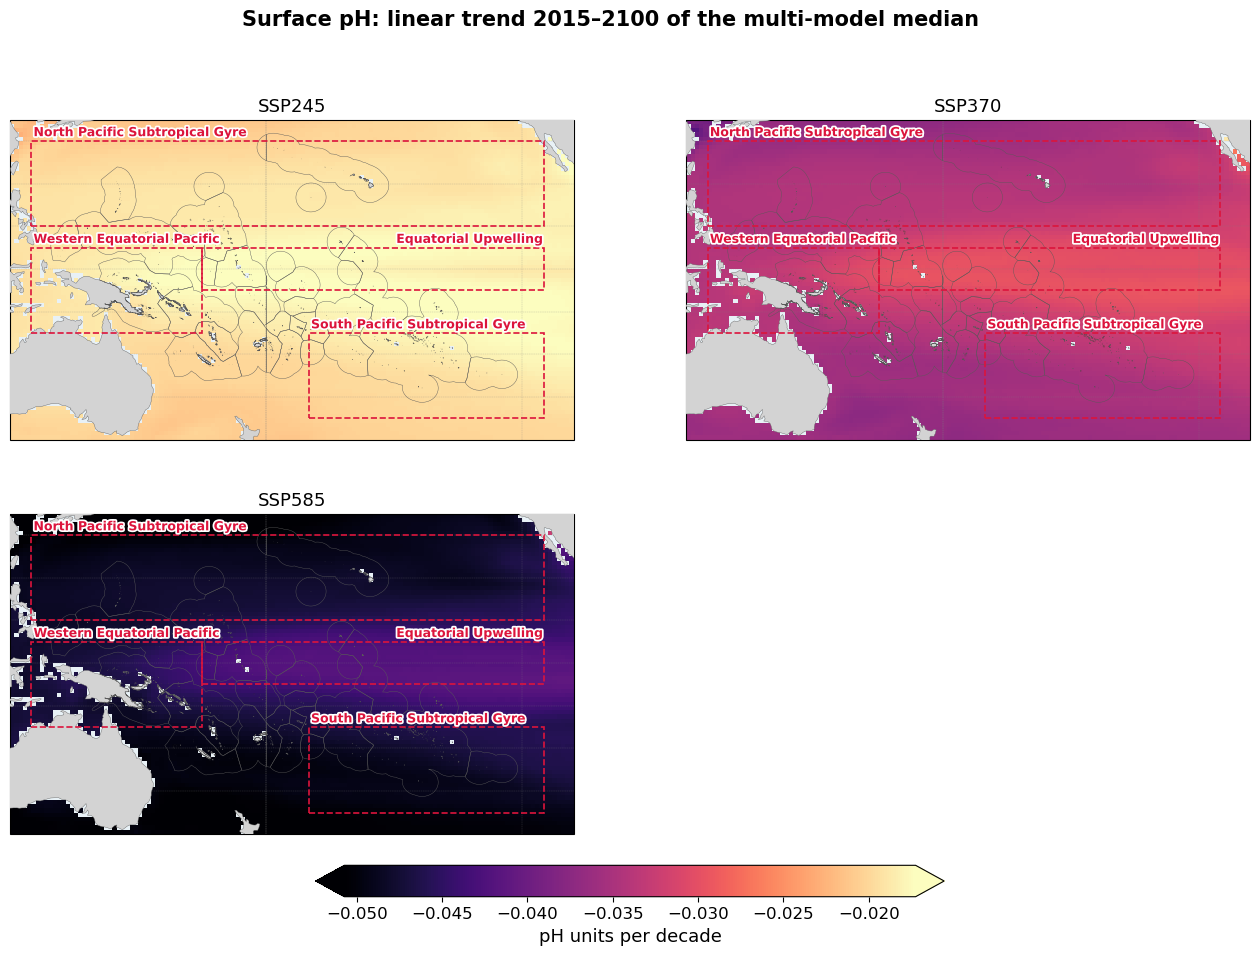

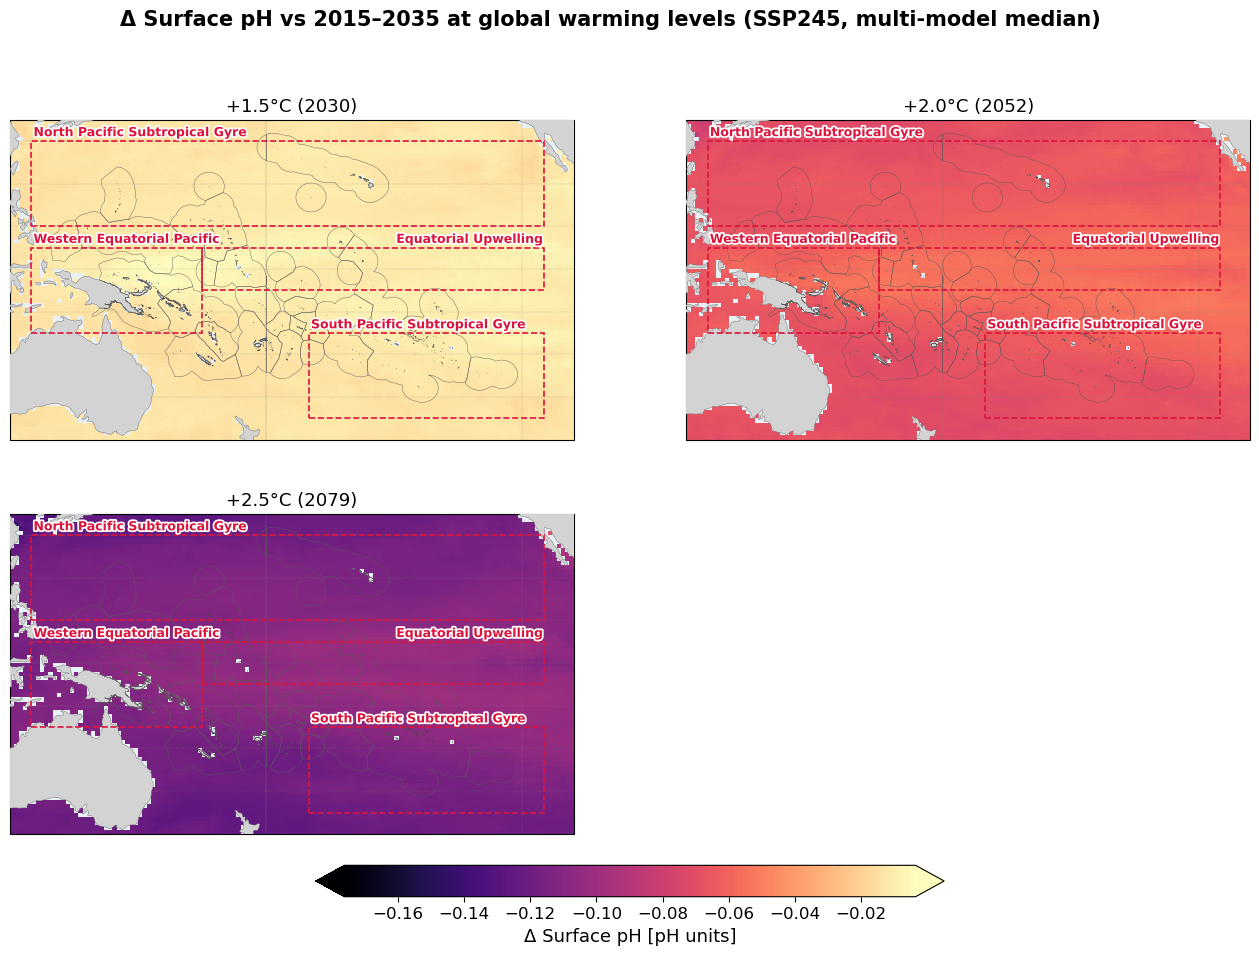

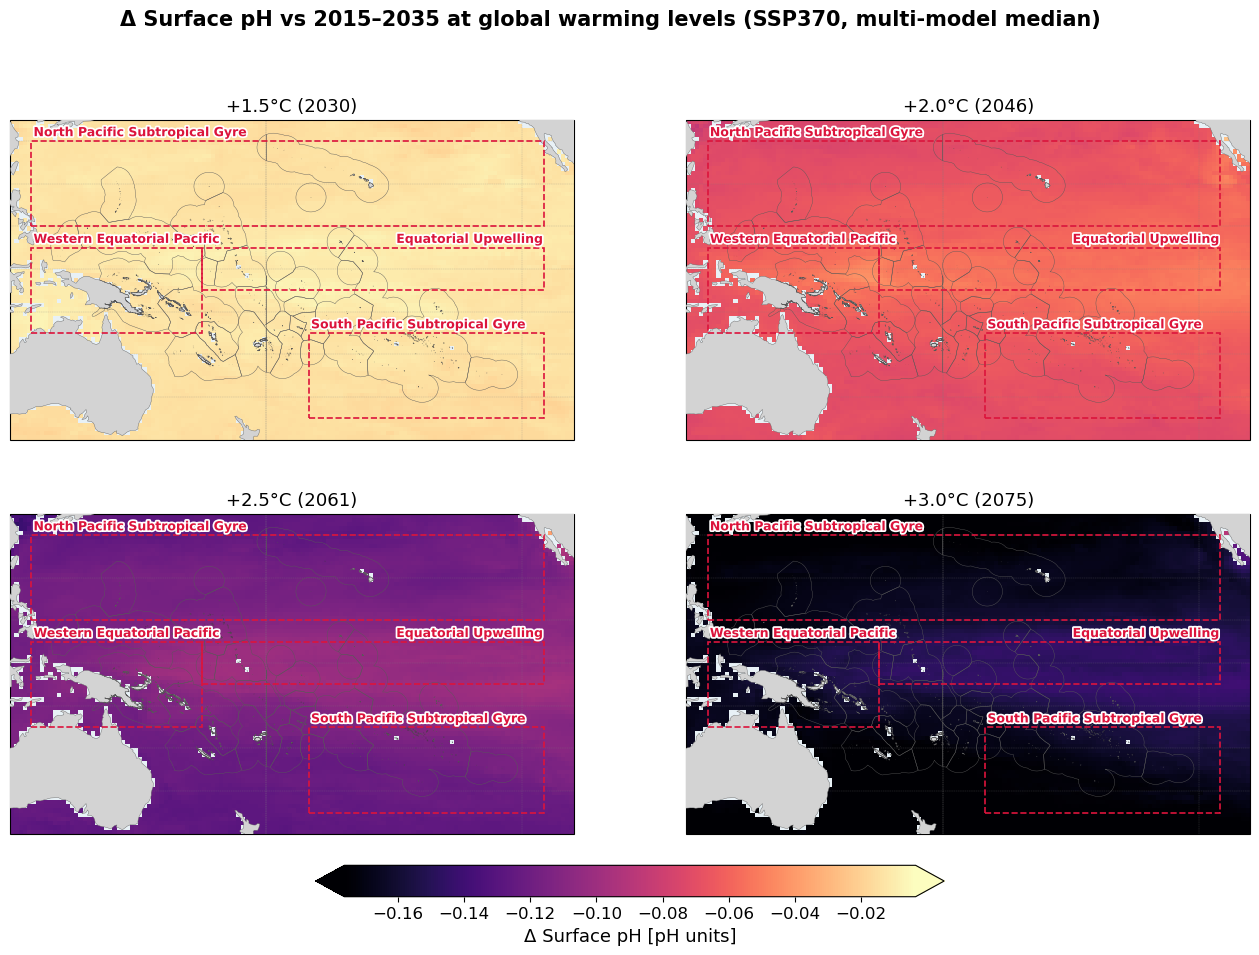

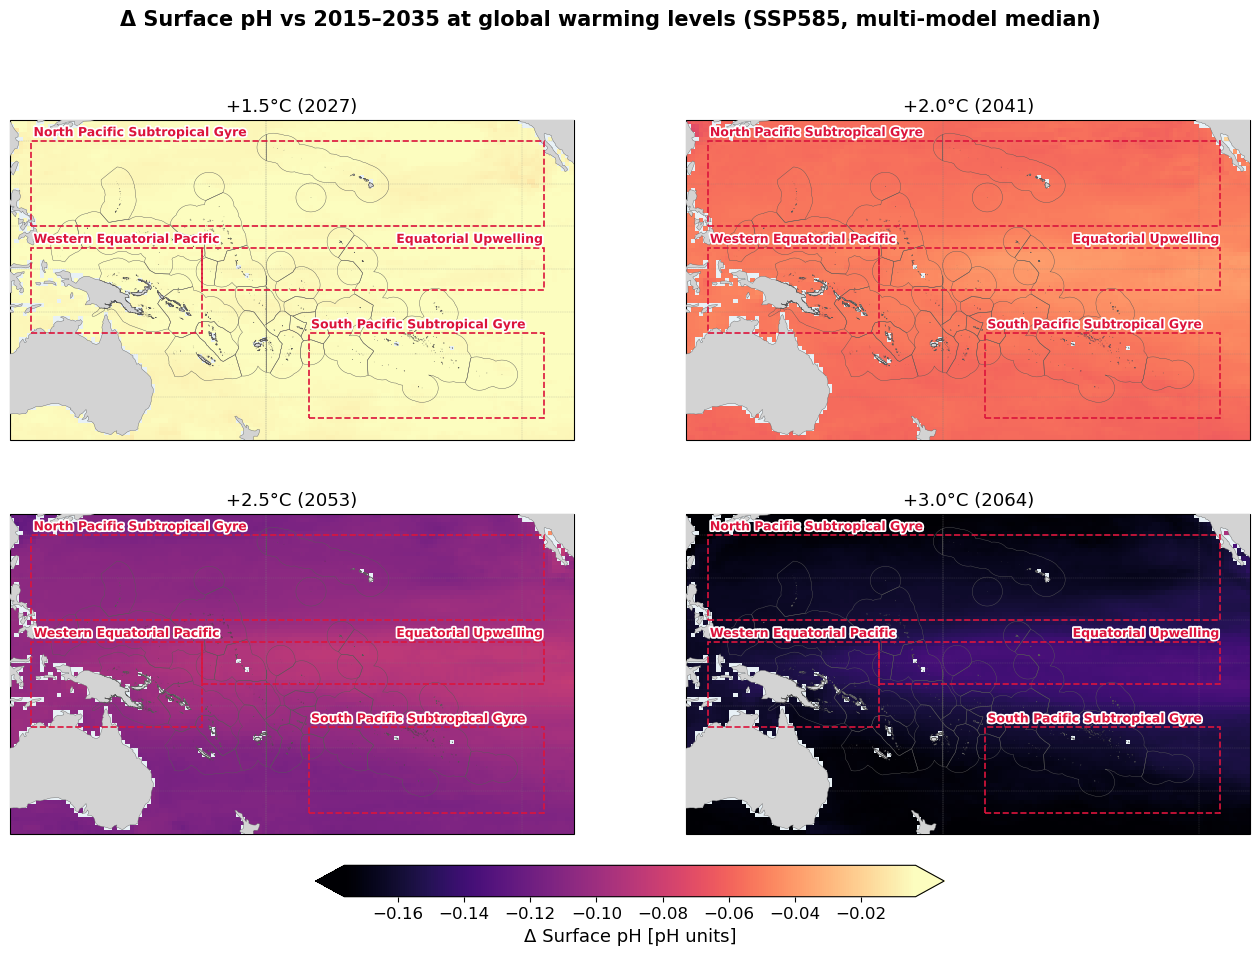

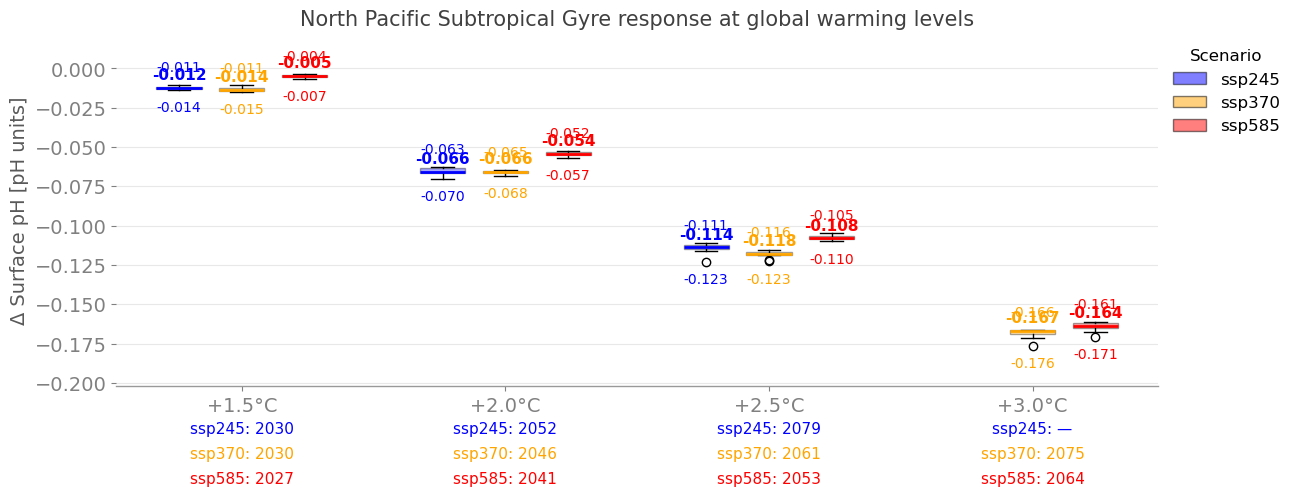

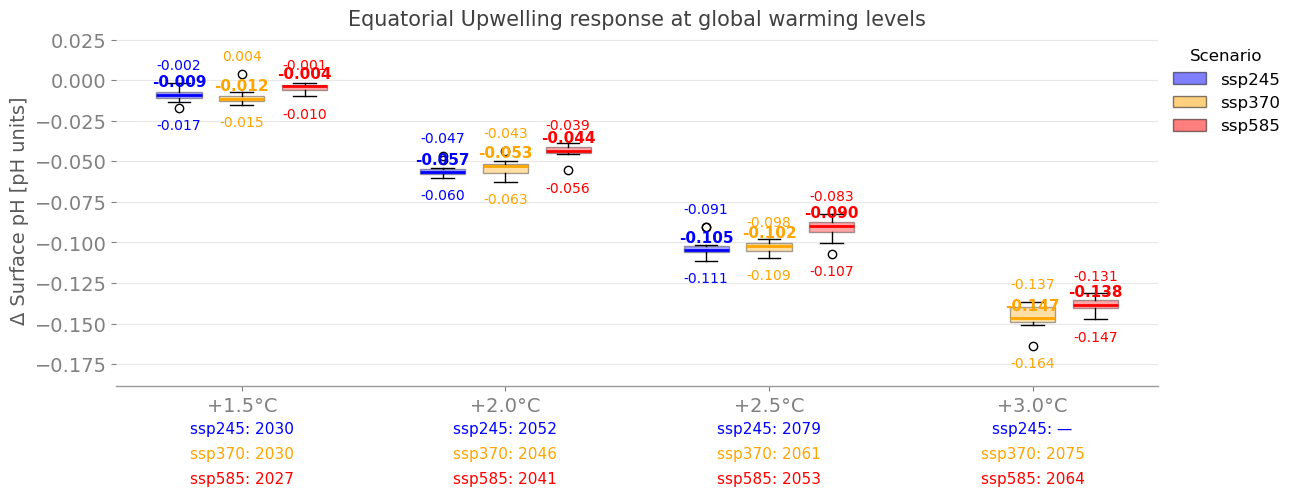

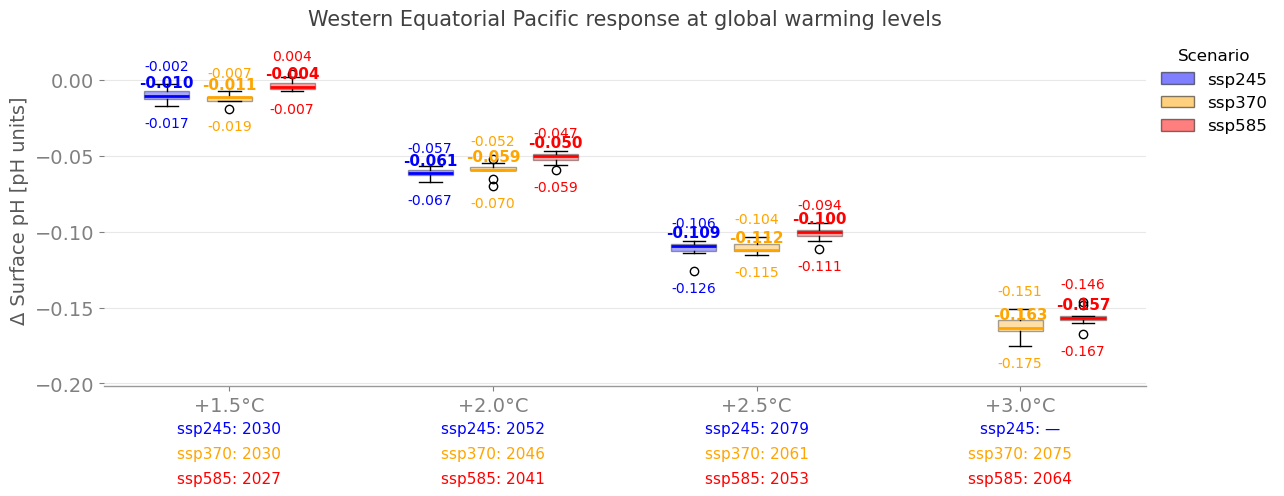

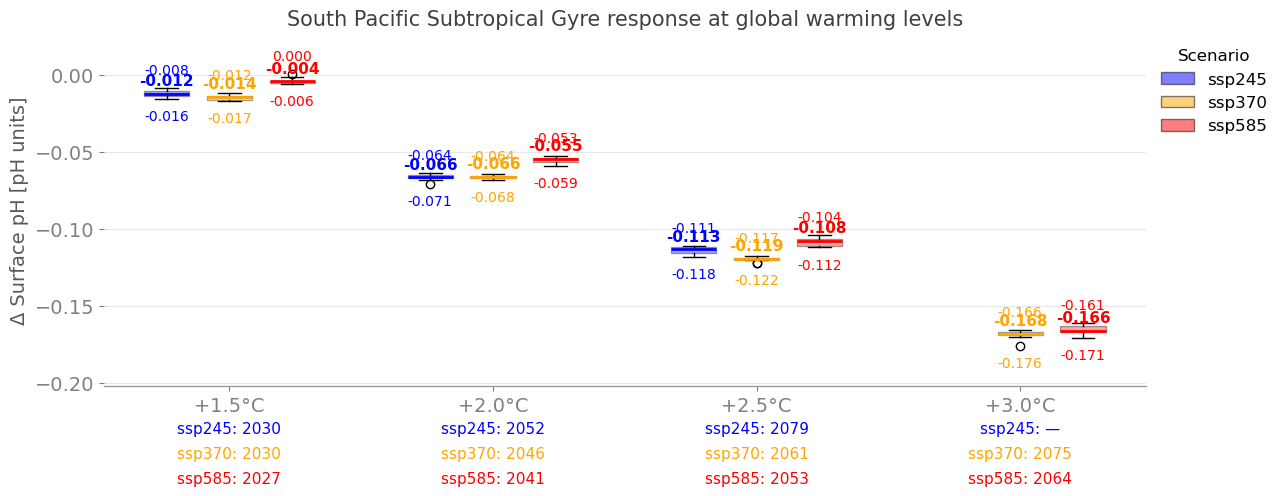

In [4]:
ds_ph = reg.extract_atlas_ph_regional(eez, ssp_scenarios)    # means over the ocean regions
grid_ph = reg.extract_atlas_ph_grid(ssp_scenarios)           # annual fields over the Pacific window (maps)
figs, tables = reg.biochem_indicator_report(ds_ph, grid_ph, "ph", scenario_info, eez, ssp_scenarios, map_scenario,
                                            fig_dir, tables_dir)
glue("ph_fig", figs["levels"], display=False)
reg.show_tables(tables)


## Surface pH by decade (Jiang et al., 2023)

Decadal projections of the surface ocean carbonate system on a 1° grid (median of the CMIP6 Earth system models; [Jiang et al., 2023](https://www.ncei.noaa.gov/data/oceans/ncei/ocads/metadata/0259391.html)), mapped over the whole Pacific window and averaged over the four ocean regions (North Pacific Subtropical Gyre, Equatorial Upwelling, Western Equatorial Pacific and South Pacific Subtropical Gyre). The decadal series of the median product are shown in each region; the fields of the individual Earth system models give the spread across models at the global warming levels (box plots).

In [5]:
ssp_scenarios_ocads = ["ssp126", "ssp245", "ssp370", "ssp585"]

**pH: change 2020–2100 of the median product (pH units), by ocean region**

scenario,SSP126,SSP245,SSP370,SSP585
region,,,,
North Pacific Subtropical Gyre,-0.0317,-0.1362,-0.2615,-0.3660
Equatorial Upwelling,-0.0323,-0.1227,-0.2294,-0.3237
Western Equatorial Pacific,-0.0366,-0.1345,-0.2550,-0.3558
South Pacific Subtropical Gyre,-0.0337,-0.1351,-0.2652,-0.3669


**pH by decade in the ocean regions (median product, pH units)**

scenario                             ssp126  ssp245  ssp370  ssp585
region                         Year                                
Equatorial Upwelling           2020  7.9967  7.9966  7.9955  7.9954
                               2030  7.9809  7.9779  7.9769  7.9750
                               2040  7.9612  7.9528  7.9450  7.9417
                               2050  7.9488  7.9311  7.9147  7.9043
                               2060  7.9464  7.9142  7.8883  7.8663
                               2070  7.9425  7.8955  7.8542  7.8157
                               2080  7.9451  7.8811  7.8222  7.7633
                               2090  7.9467  7.8703  7.7884  7.7092
                               2100  7.9644  7.8738  7.7661  7.6716
North Pacific Subtropical Gyre 2020  8.0512  8.0513  8.0508  8.0509
                               2030  8.0309  8.0273  8.0236  8.0218
                               2040  8.0118  8.0008  7.9895  7.9844
                               2050  8.0032  7.9788  7.9587  7.9442
                               2060  7.9982  7.9573  7.9245  7.8953
                               2070  7.9977  7.9400  7.8899  7.8435
                               2080  8.0025  7.9275  7.8567  7.7884
                               2090  8.0080  7.9158  7.8185  7.7295
                               2100  8.0194  7.9151  7.7893  7.6848
South Pacific Subtropical Gyre 2020  8.0796  8.0781  8.0792  8.0783
                               2030  8.0559  8.0530  8.0491  8.0489
                               2040  8.0413  8.0296  8.0192  8.0141
                               2050  8.0312  8.0068  7.9861  7.9721
                               2060  8.0250  7.9843  7.9512  7.9232
                               2070  8.0268  7.9672  7.9182  7.8705
                               2080  8.0306  7.9538  7.8847  7.8149
                               2090  8.0390  7.9471  7.8518  7.7632
                               2100  8.0460  7.9430  7.8140  7.7114
Western Equatorial Pacific     2020  8.0356  8.0380  8.0346  8.0373
                               2030  8.0172  8.0170  8.0114  8.0122
                               2040  7.9971  7.9896  7.9776  7.9759
                               2050  7.9909  7.9700  7.9507  7.9387
                               2060  7.9856  7.9484  7.9181  7.8925
                               2070  7.9834  7.9308  7.8834  7.8391
                               2080  7.9869  7.9180  7.8522  7.7881
                               2090  7.9951  7.9109  7.8199  7.7351
                               2100  7.9989  7.9035  7.7796  7.6815

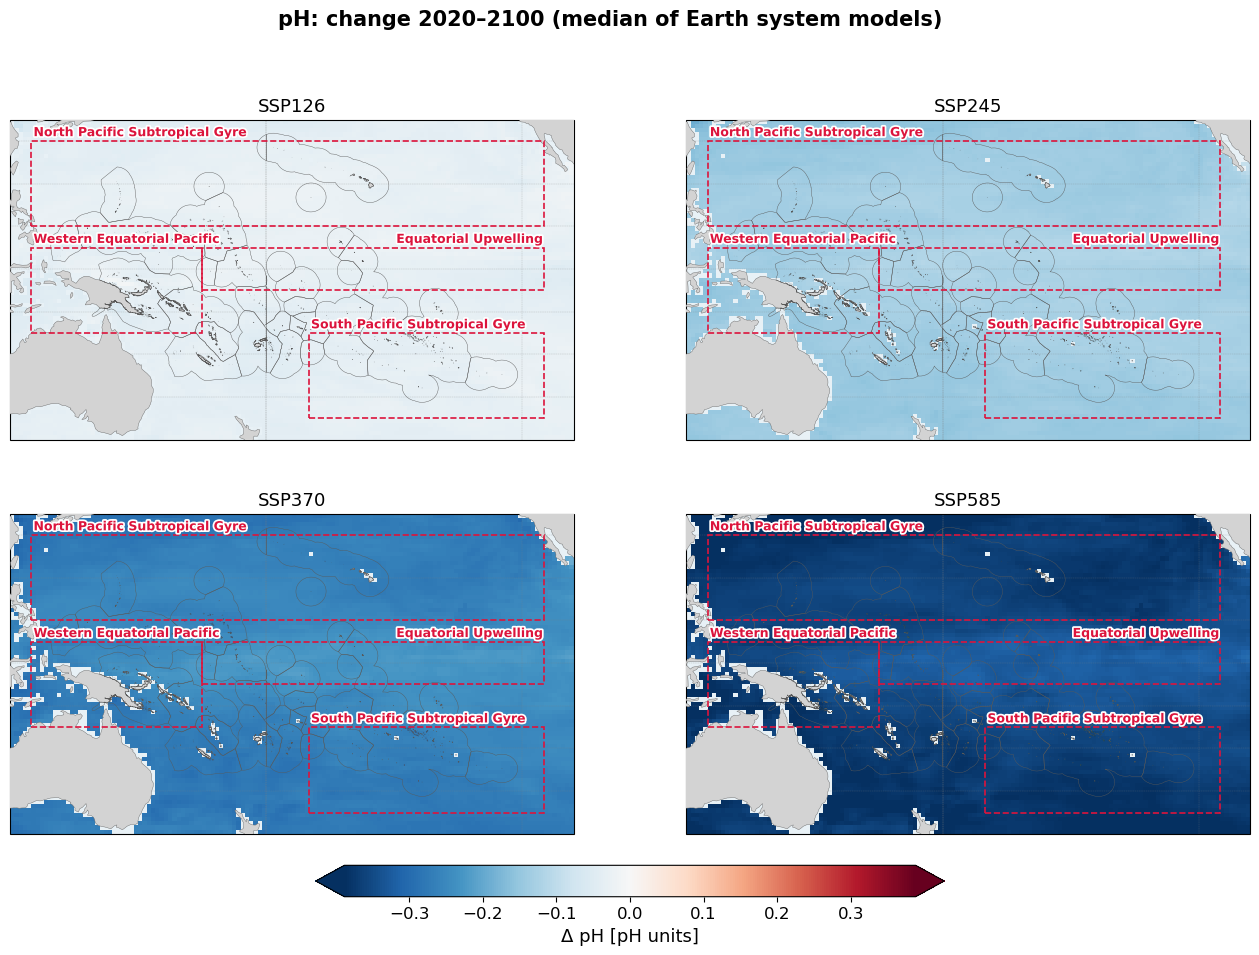

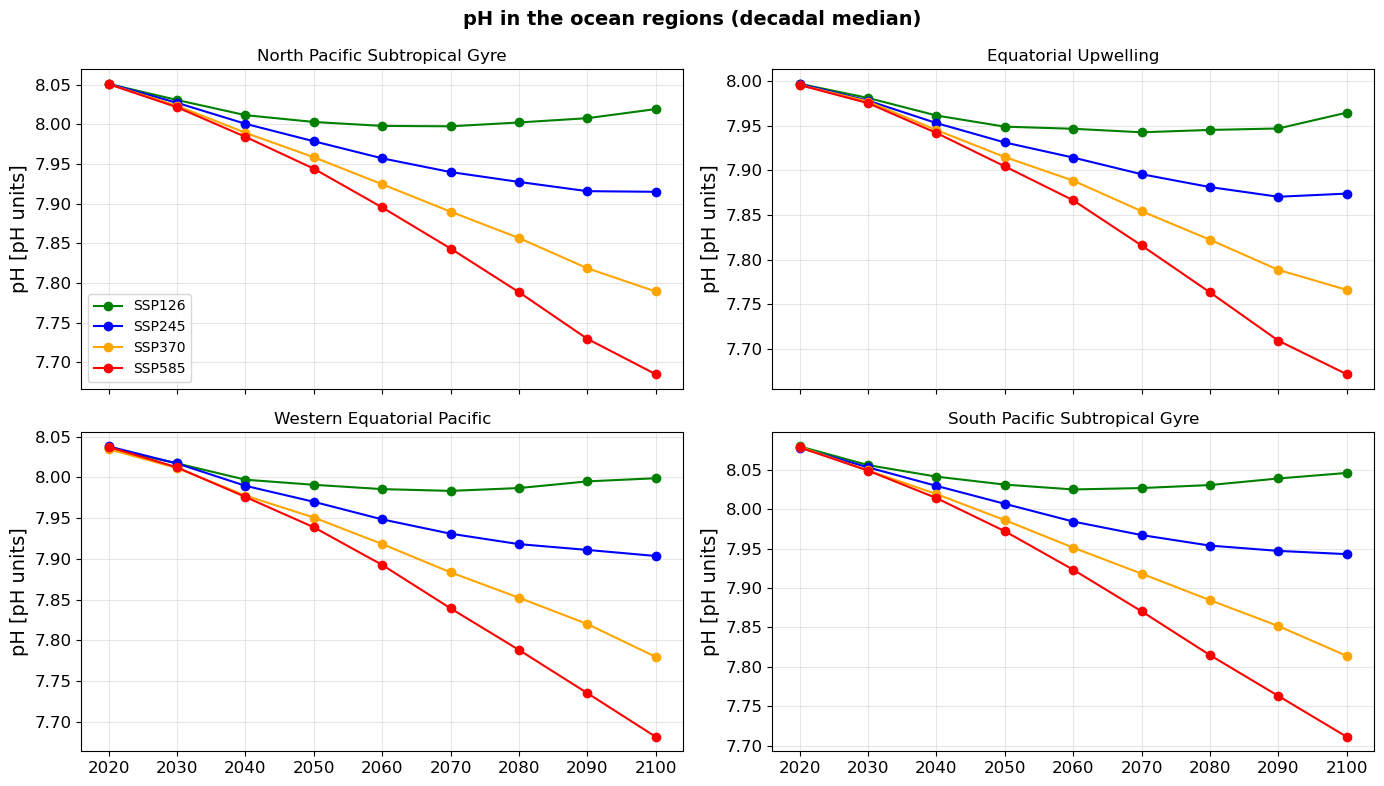

In [6]:
ds_ocads = reg.extract_ocads_regional("pHT", eez, ssp_scenarios_ocads)
figs, tables = reg.ocads_report(ds_ocads, "pHT", "pH", "pH units", eez, ssp_scenarios_ocads, fig_dir, tables_dir, cmap="RdBu_r")
reg.show_tables(tables)


### Surface pH at global warming levels (Jiang et al., 2023, Earth system models)

Every Earth system model of Jiang et al. (2023) (`bio/nc/ESMs`) averaged over the four ocean regions. The decadal values are interpolated linearly to annual values, so the warming-level years of the national projections can be used, and expressed as the change relative to each model's 2020–2030 mean (the IPCC Atlas box plots above use 2015–2035). Box plots show the spread across models in each region; not every model ran every scenario.


{'ssp126': 11, 'ssp245': 13, 'ssp370': 11, 'ssp585': 14}


**Surface pH: linear trend 2020–2100 of the multi-model median (pH units per decade), by ocean region**

,SSP126,SSP245,SSP370,SSP585
North Pacific Subtropical Gyre,-0.00376,-0.01819,-0.03356,-0.04780
Equatorial Upwelling,-0.00452,-0.01667,-0.03009,-0.04285
Western Equatorial Pacific,-0.00416,-0.01753,-0.03181,-0.04543
South Pacific Subtropical Gyre,-0.00339,-0.01792,-0.03353,-0.04776


**Δ Surface pH vs 2020–2030 at the global warming levels (pH units): spread across Earth system models by ocean region**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,11,-0.0138,-0.0159,-0.0127,-0.0160,-0.0125
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,13,-0.0117,-0.0155,-0.0100,-0.0157,-0.0093
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,11,-0.1648,-0.1682,-0.1567,-0.1701,-0.1539
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,14,-0.0056,-0.0069,-0.0050,-0.0084,-0.0049
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,14,-0.0535,-0.0579,-0.0484,-0.0579,-0.0462
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,14,-0.1062,-0.1114,-0.1000,-0.1146,-0.0988


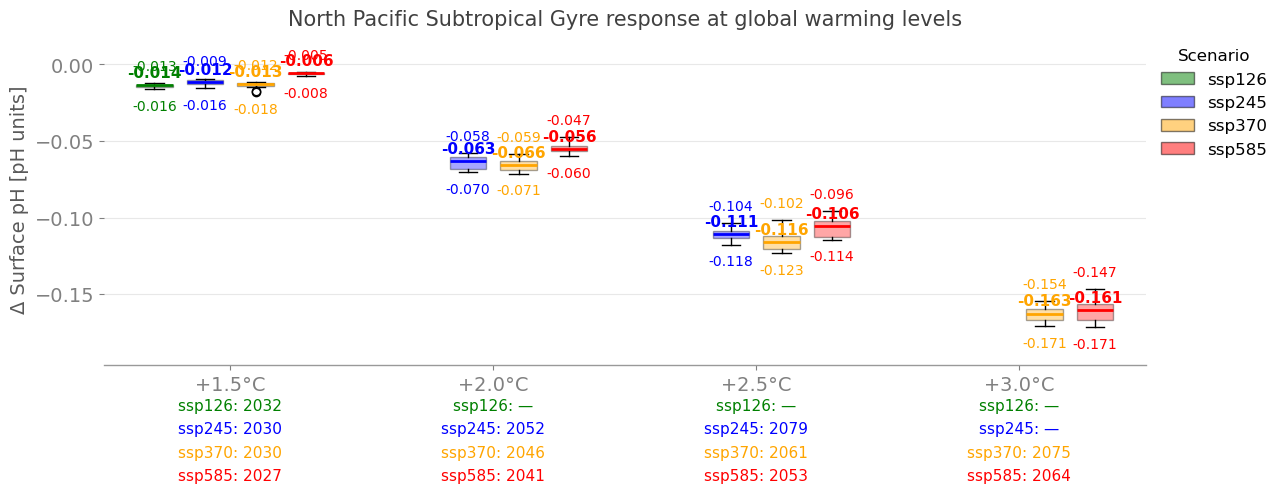

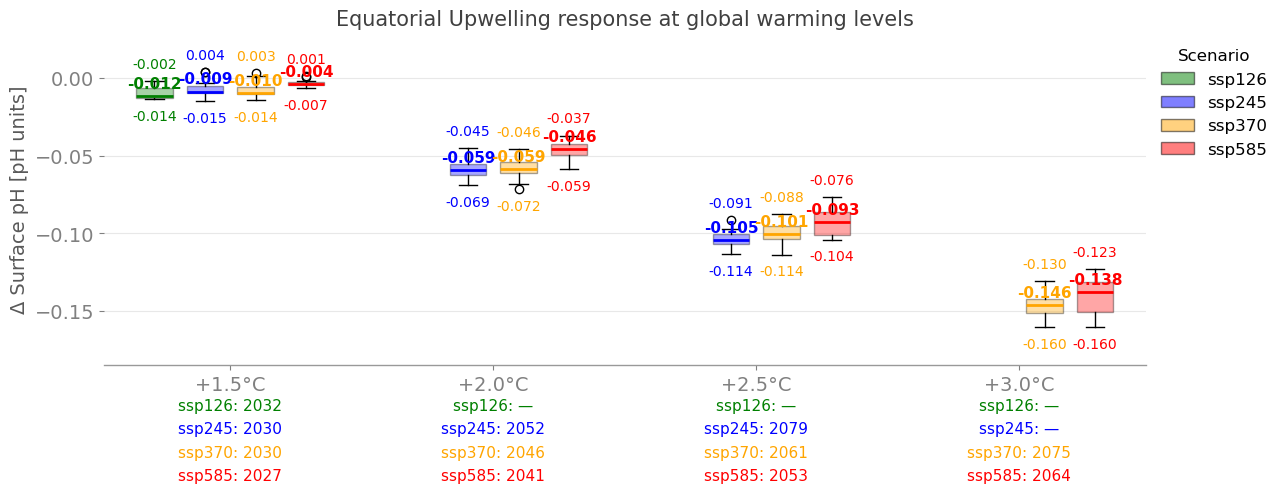

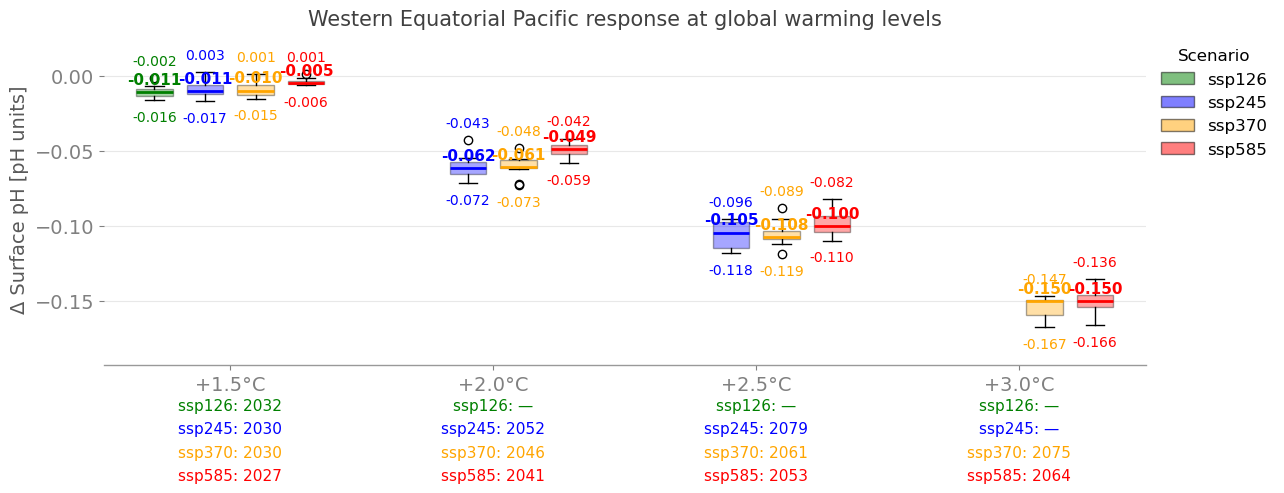

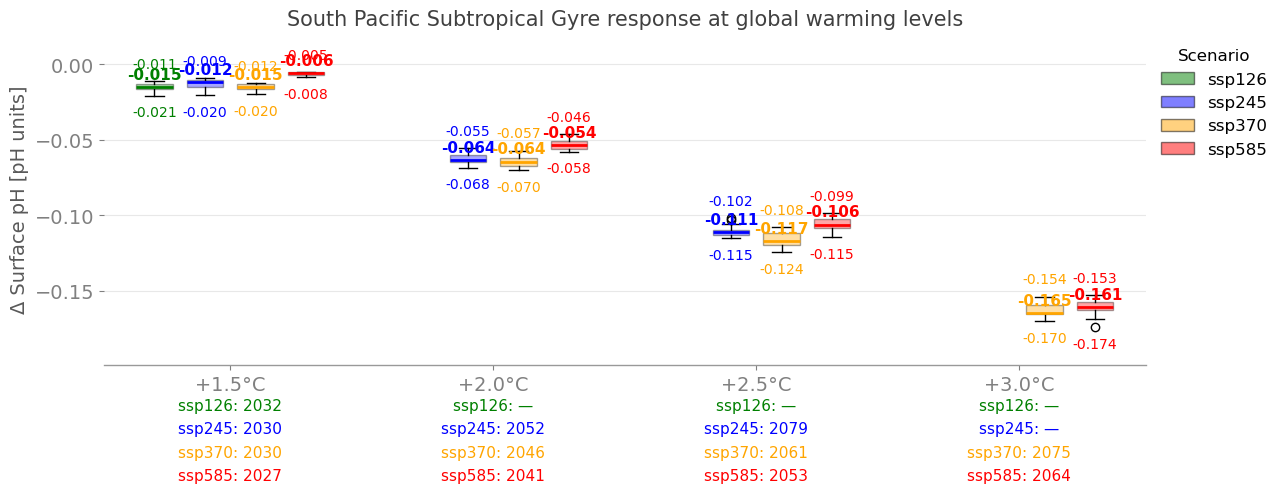

In [7]:
ds_models = reg.extract_ocads_models_regional("pHT", eez, ssp_scenarios_ocads)
print({sc: int(ds_models["pHT"].sel(scenario=sc).notnull().any(("time", "region")).sum()) for sc in ssp_scenarios_ocads})  # models per scenario
scenario_info_ocads = prj.load_warming_levels(ssp_scenarios_ocads)
figs_gwl, tables_gwl = reg.ocads_model_analysis(ds_models, "pHT", "Surface pH", "pH units", scenario_info_ocads,
                                                ssp_scenarios_ocads, fig_dir, tables_dir)
reg.show_tables(tables_gwl)
